# TP5 — Séries temporelles : prévoir la demande de vélos en libre-service (Correction)

Cours associé : [TP5_Cours.md](TP5_Cours.md) · Pense-bête : [Pense_bete_Pandas.md](../Pense_bete_Pandas.md)

## Contexte

Capital Bikeshare, l'opérateur de vélos en libre-service de Washington DC, doit chaque soir décider combien de vélos redistribuer et combien d'agents mobiliser le lendemain. Il vous demande un modèle qui **prévoit le nombre total de locations du lendemain**.

Le fichier `data/bike_sharing_day.csv` contient le nombre de locations par jour en 2011 et 2012, avec des informations de calendrier et de météo :

| Colonne | Signification |
|---|---|
| `dteday` | date |
| `holiday`, `workingday` | jour férié ; jour ouvré (ni férié, ni week-end) |
| `weathersit` | météo : 1 = dégagé, 2 = brume / nuageux, 3 = pluie ou neige légère, 4 = intempéries |
| `temp`, `atemp` | température et température ressentie, normalisées (÷ 41 et ÷ 50 °C) |
| `hum`, `windspeed` | humidité et vent, normalisés |
| `casual`, `registered` | locations par des usagers occasionnels / abonnés |
| `cnt` | **nombre total de locations** (cible) |

## Déroulé

| Partie | Contenu |
|---|---|
| 1 | Exploration et décomposition de la série |
| 2 | Découpage temporel et références naïves |
| 3 | Modèle ARIMA |
| 4 | Approche supervisée avec XGBoost |
| 5 | Synthèse |
| 6 | *Facultatif* : approfondissements |

Les cellules marquées `# TODO` sont à compléter. Les cellules ✍️ attendent une réponse rédigée.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", module="statsmodels")
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (12, 4)
RANDOM_STATE = 42

## Partie 1 — Exploration et décomposition de la série

**1.1** Chargez les données dans `df` en convertissant `dteday` en date et en l'utilisant comme index. Vérifiez qu'il n'y a ni date manquante ni doublon : l'index doit couvrir tous les jours du 1ᵉʳ janvier 2011 au 31 décembre 2012.

*Indice : `pd.date_range(debut, fin, freq="D")` construit la liste complète des jours.*

In [2]:
# TODO : chargement avec index de dates et contrôles
df = pd.read_csv("data/bike_sharing_day.csv", parse_dates=["dteday"], index_col="dteday")
df = df.asfreq("D")   # fixe la fréquence quotidienne de l'index
jours = pd.date_range(df.index.min(), df.index.max(), freq="D")
print(len(df), "lignes |", len(jours), "jours attendus | doublons :", df.index.duplicated().sum())
df.head()

731 lignes | 731 jours attendus | doublons : 0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
dteday,,,,,,,,,,,,,,,
2011-01-01,1,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
2011-01-02,2,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2011-01-03,3,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
2011-01-04,4,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
2011-01-05,5,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**1.2** Tracez la série `cnt`, avec par-dessus sa moyenne mobile sur 30 jours. Décrivez ce que vous voyez (tendance, saisonnalité, valeurs extrêmes).

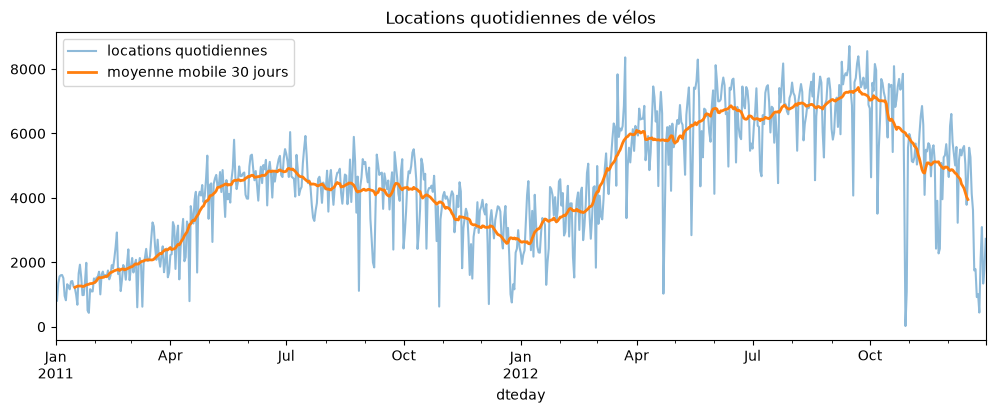

In [3]:
# TODO : série et moyenne mobile
y = df["cnt"]
y.plot(alpha=0.5, label="locations quotidiennes")
y.rolling(30, center=True).mean().plot(label="moyenne mobile 30 jours", linewidth=2)
plt.legend()
plt.title("Locations quotidiennes de vélos")
plt.show()

**1.3** Affichez les 5 jours avec le moins de locations. Que s'est-il passé ? (Cherchez les dates si besoin.)

In [4]:
# TODO : jours extrêmes
df.nsmallest(5, "cnt")[["cnt", "weathersit", "temp", "holiday"]]

,cnt,weathersit,temp,holiday
dteday,,,,
2012-10-29,22,3,0.440000,0
2011-01-27,431,1,0.195000,0
2012-12-26,441,3,0.243333,0
2011-01-26,506,3,0.217500,0
2011-03-06,605,2,0.376522,0


**1.4** Calculez le nombre moyen de locations par **jour de la semaine** et par **mois**, en distinguant usagers occasionnels (`casual`) et abonnés (`registered`). Les deux populations se comportent-elles de la même façon ?

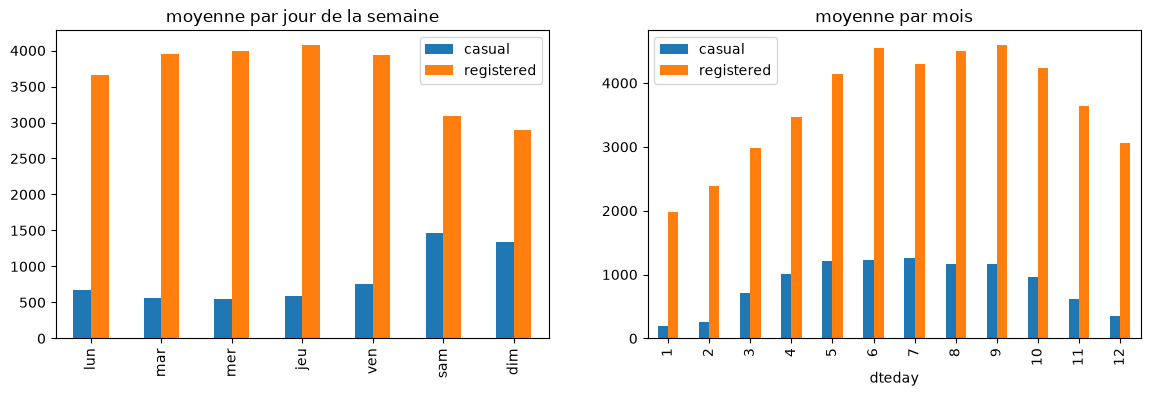

In [5]:
# TODO : profils hebdomadaire et mensuel
jours_semaine = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
par_jour = df.groupby(df.index.dayofweek)[["casual", "registered"]].mean()
par_jour.index = jours_semaine
par_jour.plot.bar(ax=axes[0], title="moyenne par jour de la semaine")
df.groupby(df.index.month)[["casual", "registered"]].mean().plot.bar(ax=axes[1], title="moyenne par mois")
plt.show()

✅ **Éléments de réponse**

- **Tendance** : la demande augmente nettement de 2011 à 2012 (le service se développe).
- **Saisonnalité annuelle** : creux en hiver, pic de mai à septembre, fortement liée à la température.
- **Saisonnalité hebdomadaire** : visible sur le profil par jour de la semaine.
- **Valeurs extrêmes** : le 29 octobre 2012 (22 locations) correspond à l'**ouragan Sandy** ; d'autres creux correspondent à des tempêtes de neige (janvier 2011, lendemain de Noël 2012) ou de fortes pluies (`weathersit = 3`). Ce sont des événements imprévisibles à partir de la série seule, mais en partie expliqués par la météo.
- Les **abonnés** utilisent surtout le vélo en semaine (≈ 4 000 par jour contre ≈ 3 000 le week-end : trajets domicile-travail), les **occasionnels** surtout le week-end (≈ 1 400 contre ≈ 600 : loisirs). Ces deux comportements opposés se compensent presque dans le total, qui varie peu selon le jour de la semaine. Les deux sont plus nombreux en été, mais la saisonnalité des occasionnels est plus marquée.

**1.5** Décomposez la série `y` avec `seasonal_decompose` (modèle additif, période 7). Qu'est-ce que la composante « tendance » capture ici ? Quelle est l'amplitude de la saisonnalité hebdomadaire ?

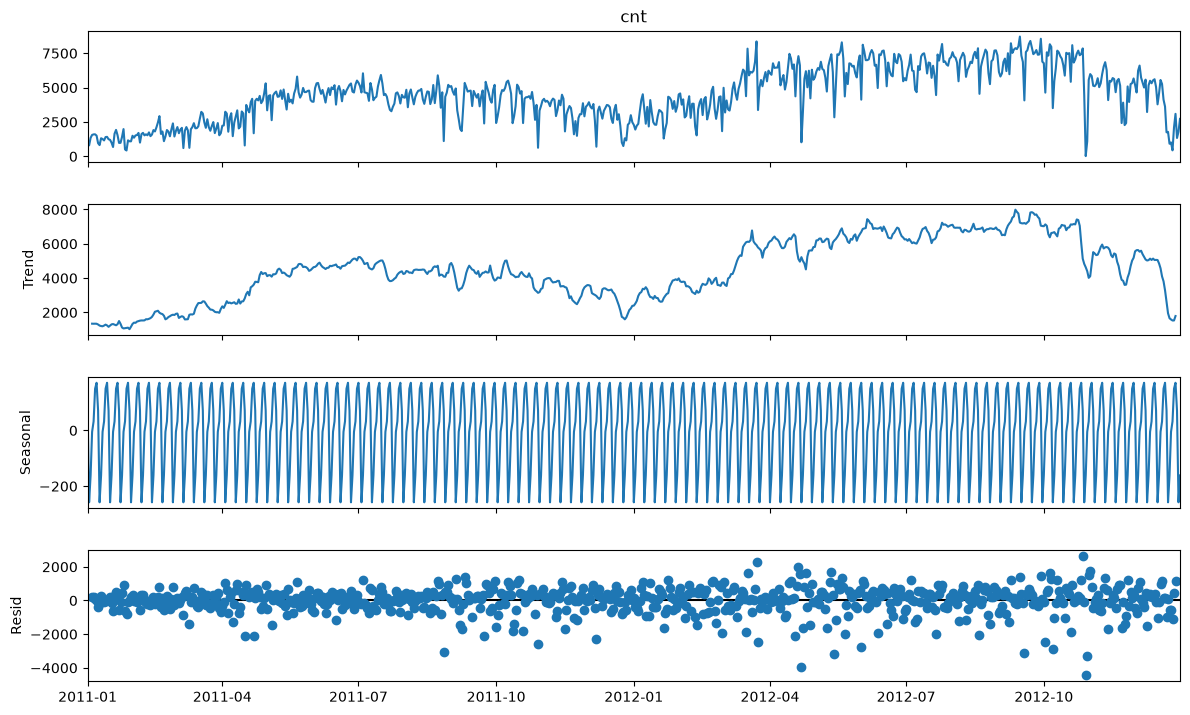

amplitude de la saisonnalité hebdomadaire : 429


In [6]:
# TODO : décomposition
decomp = seasonal_decompose(y, model="additive", period=7)
decomp.plot()
plt.gcf().set_size_inches(12, 8)
plt.show()
print("amplitude de la saisonnalité hebdomadaire :", round(decomp.seasonal.max() - decomp.seasonal.min()))

✅ **Éléments de réponse**

Avec une période de 7, la « tendance » est une moyenne mobile sur une semaine : elle capture à la fois la vraie tendance de fond **et** la saisonnalité annuelle. La composante saisonnière hebdomadaire est faible (environ 430 locations d'amplitude, pour une moyenne de 4 500 par jour) car les comportements des abonnés et des occasionnels se compensent. Les résidus restent importants et contiennent les effets de la météo.

## Partie 2 — Découpage temporel et références naïves

On évalue les modèles sur les **trois derniers mois** (octobre à décembre 2012), en **prévision à un pas** : chaque soir, on prévoit la journée du lendemain en connaissant tout le passé.

**2.1** Créez `y_train` (jusqu'au 30 septembre 2012 inclus) et `y_test` (à partir du 1ᵉʳ octobre 2012). Tracez-les avec deux couleurs.

639 jours d'entraînement | 92 jours de test


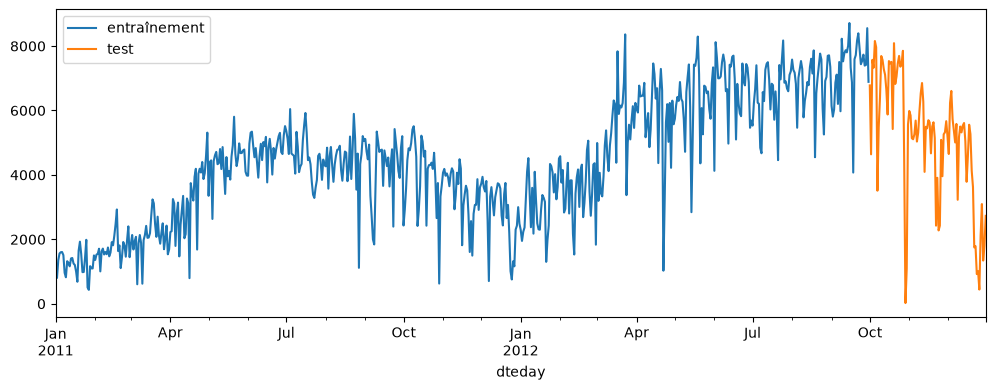

In [7]:
DATE_COUPURE = "2012-10-01"
# TODO : découpage temporel
y_train = y[y.index < DATE_COUPURE]
y_test = y[y.index >= DATE_COUPURE]
print(len(y_train), "jours d'entraînement |", len(y_test), "jours de test")
y_train.plot(label="entraînement")
y_test.plot(label="test")
plt.legend()
plt.show()

La fonction suivante mémorise les métriques de chaque méthode sur le jeu de test : MAE, RMSE, erreur relative médiane et **biais** (erreur moyenne ; positif si le modèle sous-estime).

In [8]:
resultats = {}

def evaluer(nom, prevision):
    prevision = prevision.loc[y_test.index]
    resultats[nom] = {
        "MAE": mean_absolute_error(y_test, prevision),
        "RMSE": root_mean_squared_error(y_test, prevision),
        "MAPE (%)": (np.abs(y_test - prevision) / y_test).median() * 100,   # médiane : robuste au jour de l'ouragan
        "biais": (y_test - prevision).mean(),   # > 0 : le modèle sous-estime en moyenne
    }
    return pd.DataFrame(resultats).T.round(1)

**2.2** Calculez et évaluez trois prévisions naïves à un pas sur la période de test :

- **persistance** : la valeur de la veille ;
- **naïve saisonnière** : la valeur du même jour la semaine précédente ;
- **moyenne des 7 derniers jours**.

*Indice : ces prévisions se calculent sur la série complète `y` avec `shift` et `rolling`, puis on ne garde que la période de test.*

In [9]:
# TODO : prévisions naïves
evaluer("persistance (J-1)", y.shift(1))
evaluer("naïve saisonnière (J-7)", y.shift(7))
evaluer("moyenne 7 derniers jours", y.shift(1).rolling(7).mean())

,MAE,RMSE,MAPE (%),biais
persistance (J-1),951.7,1380.2,11.2,-45.2
naïve saisonnière (J-7),1457.6,2047.2,16.9,-439.5
moyenne 7 derniers jours,1043.1,1517.9,12.4,-240.2


✅ **Éléments de réponse**

La persistance et la moyenne des 7 derniers jours font mieux que la naïve saisonnière : la saisonnalité hebdomadaire est faible par rapport aux variations d'un jour à l'autre et aux effets météo. Ces scores sont les **références à battre**. La MAPE médiane indique qu'avec la persistance, une journée « typique » est prévue à environ 11 % près.

## Partie 3 — Modèle ARIMA

**3.1** Ajustez un modèle ARIMA(1, 1, 1) sur `y_train` : `SARIMAX(y_train, order=(1, 1, 1))`, puis `.fit(disp=False)` ; gardez le résultat dans `res`. Affichez le tableau des coefficients (`res.summary().tables[1]`). Les coefficients sont-ils significatifs (colonne `P>|z|`) ?

*Le choix des ordres (1, 1, 1) est justifié dans la partie facultative (stationnarité, autocorrélation, comparaison avec un modèle saisonnier).*

In [10]:
# TODO : ajustement ARIMA
res = SARIMAX(y_train, order=(1, 1, 1)).fit(disp=False)
print(res.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2753      0.041      6.682      0.000       0.195       0.356
ma.L1         -0.8926      0.018    -48.937      0.000      -0.928      -0.857
sigma2      7.233e+05   2.44e+04     29.635      0.000    6.75e+05    7.71e+05


✅ **Éléments de réponse**

`ar.L1` et `ma.L1` sont tous deux très significatifs (p < 0,001). Le coefficient MA(1) domine (≈ −0,89) : la prévision est avant tout une moyenne lissée des valeurs récentes, corrigée de la dernière erreur.

**3.2** Prévision **multi-pas** : prévoyez d'un coup les 92 jours de la période de test (`res.get_forecast(steps=len(y_test))`) et tracez la prévision avec son intervalle de confiance à 95 % par-dessus les vraies valeurs. Évaluez-la avec la fonction `evaluer`. Qu'observez-vous ?

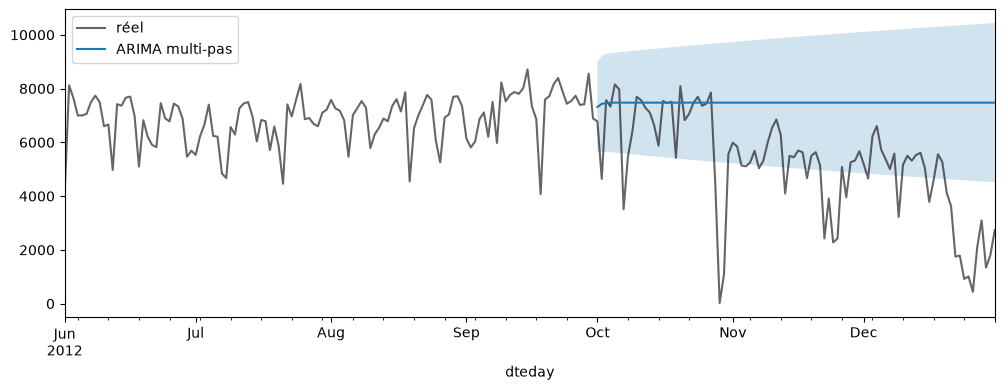

,MAE,RMSE,MAPE (%),biais
persistance (J-1),951.7,1380.2,11.2,-45.2
naïve saisonnière (J-7),1457.6,2047.2,16.9,-439.5
moyenne 7 derniers jours,1043.1,1517.9,12.4,-240.2
ARIMA multi-pas (92 jours),2371.1,3003.3,36.9,-2308.4


In [11]:
# TODO : prévision multi-pas
prev = res.get_forecast(steps=len(y_test))
moyenne = prev.predicted_mean
ic = prev.conf_int()

y.loc["2012-06":].plot(label="réel", color="black", alpha=0.6)
moyenne.plot(label="ARIMA multi-pas")
plt.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], alpha=0.2)
plt.legend()
plt.show()
evaluer("ARIMA multi-pas (92 jours)", moyenne)

✅ **Éléments de réponse**

La prévision multi-pas se contente de prolonger le dernier niveau connu (fin septembre, en pleine saison) et devient presque plate, et l'intervalle de confiance s'élargit très vite. Le modèle ne « sait » pas que l'hiver arrive : il n'a vu qu'une saison 2011–2012 et ne modélise pas la saisonnalité annuelle. L'erreur (MAE ≈ 2 400) est bien supérieure à celle des références à un pas, et le biais est fortement négatif (surestimation en hiver), mais la comparaison est injuste : **prévoir 92 jours à l'avance est bien plus difficile que prévoir le lendemain**.

**3.3** Prévision **à un pas** : on garde les paramètres appris sur l'entraînement, et on fournit au modèle les vraies valeurs au fur et à mesure. Utilisez `res.append(y_test)` pour obtenir un modèle qui connaît toute la série (sans réajuster les paramètres), puis `predict(start=DATE_COUPURE)` qui renvoie, pour chaque jour, la prévision faite la veille. Évaluez et tracez.

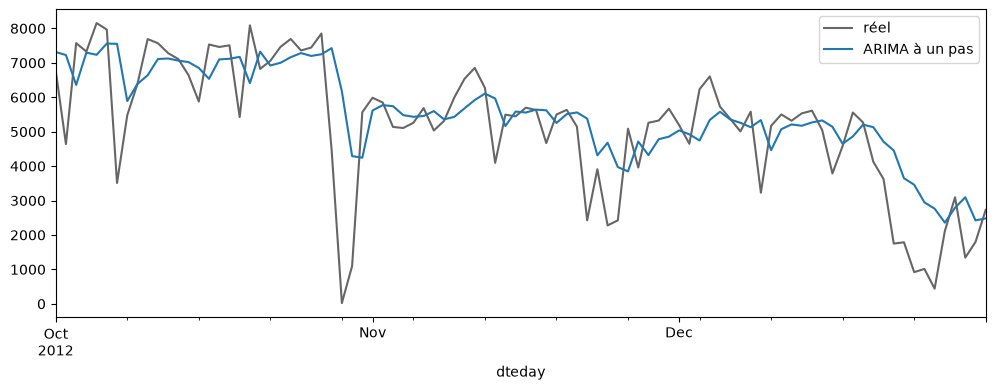

,MAE,RMSE,MAPE (%),biais
persistance (J-1),951.7,1380.2,11.2,-45.2
naïve saisonnière (J-7),1457.6,2047.2,16.9,-439.5
moyenne 7 derniers jours,1043.1,1517.9,12.4,-240.2
ARIMA multi-pas (92 jours),2371.1,3003.3,36.9,-2308.4
ARIMA à un pas,897.4,1353.0,9.2,-344.5


In [12]:
# TODO : prévision à un pas
res_complet = res.append(y_test)
prev_1pas = res_complet.predict(start=DATE_COUPURE)
y_test.plot(label="réel", color="black", alpha=0.6)
prev_1pas.plot(label="ARIMA à un pas")
plt.legend()
plt.show()
evaluer("ARIMA à un pas", prev_1pas)

✅ **Éléments de réponse**

À un pas, ARIMA ne bat que de peu la persistance (MAE ≈ 900 contre 950) : les variations d'un jour à l'autre sont dominées par la **météo** et le **calendrier** (jours fériés, week-ends), que le modèle ne connaît pas. On voit aussi qu'il réagit **avec un jour de retard** aux chutes brutales (l'ouragan Sandy, Thanksgiving, Noël), et son biais négatif (≈ −340) montre qu'il surestime la demande : elle décroît à l'approche de l'hiver et le modèle suit avec retard.

## Partie 4 — Approche supervisée avec XGBoost

On transforme la série en tableau de régression : une ligne par jour, des variables construites à partir du passé, du calendrier et de la météo.

**4.1** Construisez un DataFrame `feat` contenant :

- `lag_1`, `lag_2`, `lag_7` : les locations 1, 2 et 7 jours avant ;
- `moy_7j` : la moyenne des locations des 7 jours **précédents** (attention à la fuite de données) ;
- `jour_semaine`, `mois` : issus de l'index ;
- `holiday`, `workingday`, `weathersit`, `temp`, `hum`, `windspeed` : repris de `df` ;
- la cible `cnt`.

Supprimez les lignes contenant des valeurs manquantes (les 7 premiers jours).

In [13]:
# TODO : construction des variables
feat = pd.DataFrame(index=df.index)
feat["lag_1"] = y.shift(1)
feat["lag_2"] = y.shift(2)
feat["lag_7"] = y.shift(7)
feat["moy_7j"] = y.shift(1).rolling(7).mean()
feat["jour_semaine"] = df.index.dayofweek
feat["mois"] = df.index.month
feat[["holiday", "workingday", "weathersit", "temp", "hum", "windspeed"]] = df[
    ["holiday", "workingday", "weathersit", "temp", "hum", "windspeed"]]
feat["cnt"] = y
feat = feat.dropna()
feat.head(10)

,lag_1,lag_2,lag_7,moy_7j,jour_semaine,mois,holiday,workingday,weathersit,temp,hum,windspeed,cnt
dteday,,,,,,,,,,,,,
2011-01-08,1510.0,1606.0,985.0,1344.714286,5,1,0,0,2,0.165000,0.535833,0.266804,959
2011-01-09,959.0,1510.0,801.0,1341.000000,6,1,0,0,1,0.138333,0.434167,0.361950,822
2011-01-10,822.0,959.0,1349.0,1344.000000,0,1,0,1,1,0.150833,0.482917,0.223267,1321
2011-01-11,1321.0,822.0,1562.0,1340.000000,1,1,0,1,2,0.169091,0.686364,0.122132,1263
2011-01-12,1263.0,1321.0,1600.0,1297.285714,2,1,0,1,1,0.172727,0.599545,0.304627,1162
2011-01-13,1162.0,1263.0,1606.0,1234.714286,3,1,0,1,1,0.165000,0.470417,0.301000,1406
2011-01-14,1406.0,1162.0,1510.0,1206.142857,4,1,0,1,1,0.160870,0.537826,0.126548,1421
2011-01-15,1421.0,1406.0,959.0,1193.428571,5,1,0,0,2,0.233333,0.498750,0.157963,1248
2011-01-16,1248.0,1421.0,822.0,1234.714286,6,1,0,0,1,0.231667,0.483750,0.188433,1204


**4.2** Pourquoi faut-il écrire `y.shift(1).rolling(7).mean()` et non `y.rolling(7).mean()` ? Et pourquoi l'utilisation de la météo **du jour même** est-elle discutable ?

✅ **Éléments de réponse**

- `y.rolling(7).mean()` au jour `t` inclut `y[t]`, c'est-à-dire la valeur à prévoir : le modèle « tricherait » en voyant une partie de la réponse (**fuite de données**). Avec `shift(1)`, la fenêtre s'arrête à la veille.
- La météo du jour `t` n'est connue qu'**a posteriori**. En production, on disposerait de la **prévision** météo du lendemain, moins précise. Nos résultats sont donc un peu optimistes ; c'est un choix acceptable si on le signale.

**4.3** Découpez `feat` en `X_train`, `y_train_sup`, `X_test`, `y_test_sup` selon `DATE_COUPURE`. Entraînez un `XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8)` sur le jeu d'entraînement, prévoyez la période de test, évaluez la prévision avec `evaluer` et tracez-la. Tracez aussi l'importance des variables.

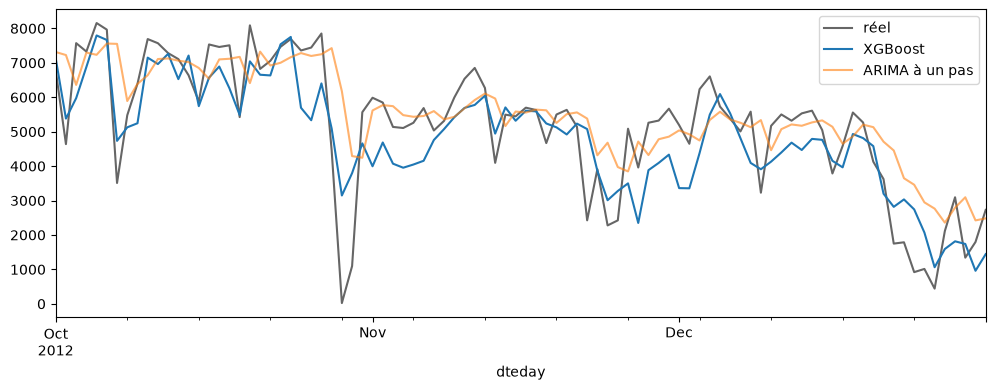

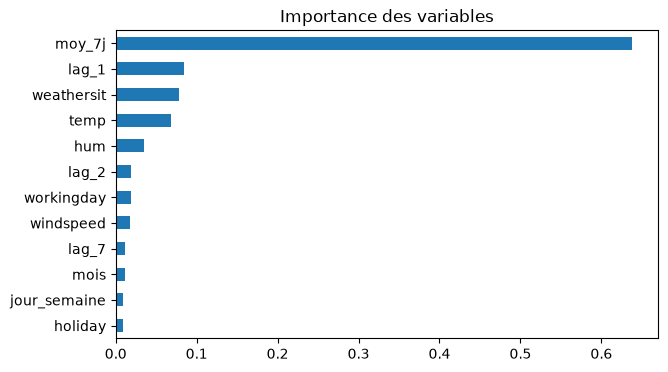

,MAE,RMSE,MAPE (%),biais
persistance (J-1),951.7,1380.2,11.2,-45.2
naïve saisonnière (J-7),1457.6,2047.2,16.9,-439.5
moyenne 7 derniers jours,1043.1,1517.9,12.4,-240.2
ARIMA multi-pas (92 jours),2371.1,3003.3,36.9,-2308.4
ARIMA à un pas,897.4,1353.0,9.2,-344.5
XGBoost (lags + calendrier + météo),858.9,1066.5,15.2,343.1


In [14]:
# TODO : découpage, entraînement, évaluation, importances
X_feat = feat.drop(columns="cnt")
X_train = X_feat[X_feat.index < DATE_COUPURE]
X_test = X_feat[X_feat.index >= DATE_COUPURE]
y_train_sup = feat.loc[feat.index < DATE_COUPURE, "cnt"]
y_test_sup = feat.loc[feat.index >= DATE_COUPURE, "cnt"]

xgb_ts = XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8,
                      random_state=RANDOM_STATE)
xgb_ts.fit(X_train, y_train_sup)
prev_xgb = pd.Series(xgb_ts.predict(X_test), index=X_test.index)

y_test.plot(label="réel", color="black", alpha=0.6)
prev_xgb.plot(label="XGBoost")
prev_1pas.plot(label="ARIMA à un pas", alpha=0.6)
plt.legend()
plt.show()

pd.Series(xgb_ts.feature_importances_, index=X_train.columns).sort_values().plot.barh(figsize=(7, 4))
plt.title("Importance des variables")
plt.show()
evaluer("XGBoost (lags + calendrier + météo)", prev_xgb)

**4.4** Pour mesurer l'apport de la météo, réentraînez le même modèle **sans** les variables météo (`weathersit`, `temp`, `hum`, `windspeed`) et évaluez-le.

In [15]:
# TODO : modèle sans météo
meteo = ["weathersit", "temp", "hum", "windspeed"]
xgb_sans_meteo = XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8,
                              random_state=RANDOM_STATE)
xgb_sans_meteo.fit(X_train.drop(columns=meteo), y_train_sup)
evaluer("XGBoost sans météo", pd.Series(xgb_sans_meteo.predict(X_test.drop(columns=meteo)), index=X_test.index))

,MAE,RMSE,MAPE (%),biais
persistance (J-1),951.7,1380.2,11.2,-45.2
naïve saisonnière (J-7),1457.6,2047.2,16.9,-439.5
moyenne 7 derniers jours,1043.1,1517.9,12.4,-240.2
ARIMA multi-pas (92 jours),2371.1,3003.3,36.9,-2308.4
ARIMA à un pas,897.4,1353.0,9.2,-344.5
XGBoost (lags + calendrier + météo),858.9,1066.5,15.2,343.1
XGBoost sans météo,1068.2,1381.7,16.9,207.8


✅ **Éléments de réponse**

- Avec la météo, XGBoost obtient la meilleure MAE et surtout une RMSE bien plus faible (≈ 1 070 contre ≈ 1 350) : il **anticipe les chutes brutales** (pluie, ouragan) grâce à `weathersit`, `temp` et `hum`, là où ARIMA et la persistance réagissent avec un jour de retard.
- En revanche, son erreur relative médiane est **moins bonne** que celle d'ARIMA, et son **biais est positif** (≈ +340 locations par jour) : il sous-estime systématiquement la demande de l'automne 2012, supérieure à celle de 2011 à météo égale. C'est l'incapacité des arbres à **extrapoler** une croissance, vue au TP4.
- Le niveau récent (`moy_7j`, `lag_1`) domine l'importance, suivi de la météo.
- Sans la météo, le modèle fait moins bien que la simple persistance : **l'essentiel du gain vient de l'information exogène**. La qualité de la prévision dépendra donc surtout de la qualité des **prévisions météo** disponibles la veille.

## Partie 5 — Synthèse

**5.1** Affichez le tableau `resultats` trié par MAE.

In [16]:
# TODO : tableau récapitulatif
pd.DataFrame(resultats).T.sort_values("MAE").round(1)

,MAE,RMSE,MAPE (%),biais
XGBoost (lags + calendrier + météo),858.9,1066.5,15.2,343.1
ARIMA à un pas,897.4,1353.0,9.2,-344.5
persistance (J-1),951.7,1380.2,11.2,-45.2
moyenne 7 derniers jours,1043.1,1517.9,12.4,-240.2
XGBoost sans météo,1068.2,1381.7,16.9,207.8
naïve saisonnière (J-7),1457.6,2047.2,16.9,-439.5
ARIMA multi-pas (92 jours),2371.1,3003.3,36.9,-2308.4


**5.2** Rédigez une recommandation pour l'opérateur : quel modèle, quelle précision, quelles données collecter, quelles limites ?

✅ **Éléments de réponse**

- **Constat** : aucune méthode ne domine sur tous les critères. XGBoost avec météo limite les grosses erreurs (meilleure RMSE) mais souffre d'un biais lié à la croissance de la demande ; ARIMA réagit en retard et surestime la demande qui décroît en fin d'année. La persistance, triviale, reste une référence difficile à battre de beaucoup.
- **Recommandation** : un modèle qui combine météo et correction du niveau. Le bonus montre deux pistes efficaces : SARIMAX avec la météo en variables exogènes, ou XGBoost prédisant le **rapport** à la moyenne récente plutôt que le niveau. On obtient alors une MAE de 760 (SARIMAX) à 840 (XGBoost sur le rapport), contre 950 pour la persistance, et SARIMAX garde une erreur relative médiane d'environ 10 %.
- **Données** : la météo est la clé. Il faut brancher le modèle sur une **API de prévisions météo** et réévaluer la précision avec ces prévisions (et non la météo observée). Le calendrier des événements (jours fériés, grandes manifestations) est aussi précieux.
- **Limites** : seulement deux ans d'historique (une seule transition 2011 → 2012 pour estimer la tendance) ; événements extrêmes (ouragan) imprévisibles ; l'évaluation couvre une seule saison (automne-hiver). Il faudra **réentraîner régulièrement** le modèle et surveiller son erreur dans le temps.
- **Pistes** : prévoir séparément `casual` et `registered`, dont les comportements diffèrent ; passer à une granularité horaire pour la redistribution des vélos entre stations.

## Partie 6 — *Facultatif* : approfondissements

*À faire si vous avez terminé le reste.* Les questions 6.1 à 6.3 justifient le choix du modèle ARIMA(1, 1, 1) de la partie 3 ; les questions 6.4 et 6.5 portent sur la validation croisée d'une série temporelle.

**6.1** Appliquez le test ADF à `y`, puis à sa différence d'ordre 1 (`y.diff()`). Concluez sur la stationnarité. Tracez la série différenciée.

série brute            p-value = 0.3427
différence d'ordre 1   p-value = 0.0000


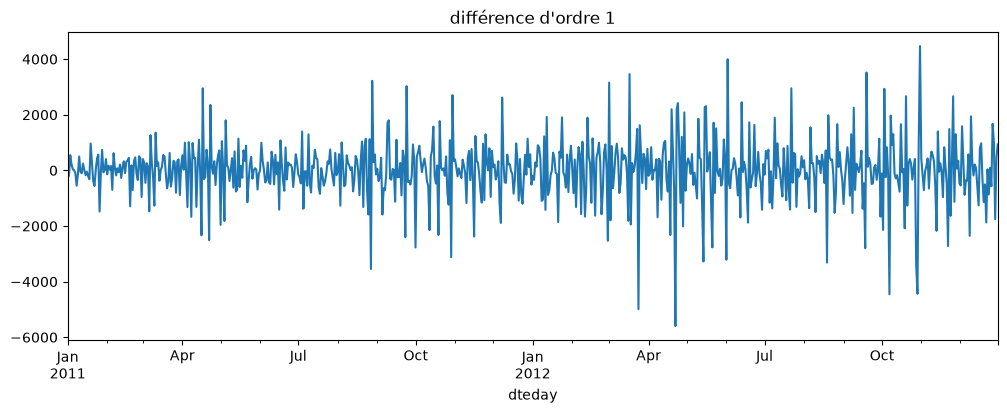

In [17]:
# TODO : test ADF
for nom, serie in [("série brute", y), ("différence d'ordre 1", y.diff())]:
    p_value = adfuller(serie.dropna())[1]
    print(f"{nom:22s} p-value = {p_value:.4f}")
y.diff().plot(title="différence d'ordre 1")
plt.show()

✅ **Éléments de réponse**

- Série brute : p-value ≈ 0,34, supérieure à 0,05 : on ne peut pas rejeter l'hypothèse de non-stationnarité, ce qui est cohérent avec la tendance et la saisonnalité annuelle visibles.
- Série différenciée : p-value quasi nulle, elle est stationnaire. Visuellement, elle oscille autour de 0, mais sa variance n'est pas parfaitement constante (plus forte en été et en 2012). Une différenciation (`d = 1`) semble donc appropriée pour un modèle ARIMA.

**6.2** Tracez l'ACF et la PACF (40 décalages) de la série **différenciée**. Quels décalages sont significatifs ?

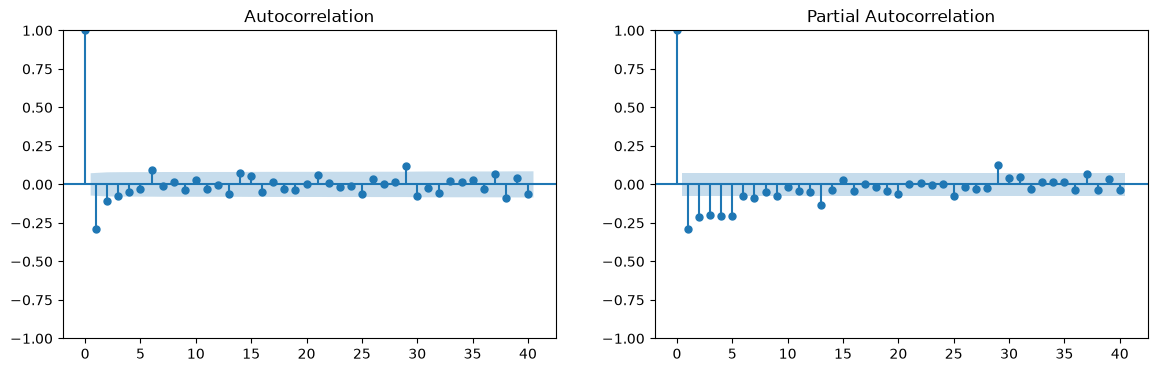

In [18]:
# TODO : ACF et PACF
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y.diff().dropna(), lags=40, ax=axes[0])
plot_pacf(y.diff().dropna(), lags=40, ax=axes[1])
plt.show()

✅ **Éléments de réponse**

- L'ACF de la série différenciée présente un fort pic **négatif au décalage 1** puis retombe rapidement : signature typique d'une composante **MA(1)** après différenciation.
- L'ACF de la série différenciée vaut environ −0,29 au décalage 1, puis devient quasi nulle.
- La PACF décroît plus progressivement sur les 5 premiers décalages (≈ −0,2), ce qui confirme une structure plutôt MA qu'AR.
- Il n'y a **pas de pic net** aux décalages 7, 14, 21 : la saisonnalité hebdomadaire est faible, comme l'a montré la décomposition.
- Un modèle de départ raisonnable est donc **ARIMA(1, 1, 1)**, celui de la partie 3.

**6.3** Une partie saisonnière de période 7 améliore-t-elle le modèle ? Ajustez `SARIMAX(y_train, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7))`, affichez ses coefficients et comparez son AIC à celui du modèle `res` de la partie 3 (plus l'AIC est faible, mieux c'est).

In [19]:
# TODO : SARIMA et comparaison des AIC
res_sarima = SARIMAX(y_train, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7)).fit(disp=False)
print(res_sarima.summary().tables[1])
print(f"AIC SARIMA : {res_sarima.aic:.1f} | AIC ARIMA(1,1,1) : {res.aic:.1f}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2753      0.041      6.658      0.000       0.194       0.356
ma.L1         -0.8926      0.018    -48.638      0.000      -0.929      -0.857
ar.S.L7       -0.9997     16.115     -0.062      0.951     -32.585      30.585
ma.S.L7        0.9997     16.111      0.062      0.951     -30.578      32.577
sigma2      7.233e+05   2.47e+04     29.334      0.000    6.75e+05    7.72e+05
AIC SARIMA : 10429.3 | AIC ARIMA(1,1,1) : 10425.3


✅ **Éléments de réponse**

- Les deux coefficients saisonniers valent ≈ −1 et ≈ +1, avec des p-values proches de 1 : ils **s'annulent** et ne sont pas significatifs. La partie saisonnière est inutile, ce qui confirme la faiblesse de la saisonnalité hebdomadaire vue à la question 1.5.
- L'AIC du simple ARIMA(1, 1, 1) est même légèrement plus faible (≈ 10 425 contre ≈ 10 429) : le modèle le plus simple est le bon choix.

**6.4** Évaluez le modèle XGBoost de la partie 4 par **validation croisée temporelle** sur le jeu d'entraînement (`TimeSeriesSplit(n_splits=5)`, score MAE). Affichez la MAE de chaque pli.

In [20]:
# TODO : validation croisée temporelle
tscv = TimeSeriesSplit(n_splits=5)
mae_cv = -cross_val_score(xgb_ts, X_train, y_train_sup, cv=tscv, scoring="neg_mean_absolute_error")
print("MAE par pli :", mae_cv.round(0))

MAE par pli : [ 741.  637.  628. 1590.  704.]


**6.5** Les MAE des plis sont très différentes. Affichez les périodes de validation de chaque pli (`tscv.split(X_train)`) pour comprendre pourquoi.

In [21]:
# TODO : périodes des plis
for i, (idx_train, idx_val) in enumerate(tscv.split(X_train)):
    print(f"pli {i + 1} : train jusqu'au {X_train.index[idx_train[-1]].date()} | "
          f"validation du {X_train.index[idx_val[0]].date()} au {X_train.index[idx_val[-1]].date()} "
          f"| MAE = {mae_cv[i]:.0f}")

pli 1 : train jusqu'au 2011-04-24 | validation du 2011-04-25 au 2011-08-07 | MAE = 741
pli 2 : train jusqu'au 2011-08-07 | validation du 2011-08-08 au 2011-11-20 | MAE = 637
pli 3 : train jusqu'au 2011-11-20 | validation du 2011-11-21 au 2012-03-04 | MAE = 628
pli 4 : train jusqu'au 2012-03-04 | validation du 2012-03-05 au 2012-06-17 | MAE = 1590
pli 5 : train jusqu'au 2012-06-17 | validation du 2012-06-18 au 2012-09-30 | MAE = 704


✅ **Éléments de réponse**

Chaque pli valide sur une période différente de l'année, avec plus ou moins d'historique. Le pli 4 (mars à juin 2012) est de loin le pire : la demande du printemps 2012 dépasse largement tout ce qui a été observé en 2011 à météo et saison égales. Or un modèle à base d'arbres **ne sait pas extrapoler** (TP4) : il ne peut pas prédire des niveaux jamais vus, et sous-estime systématiquement. La validation croisée temporelle révèle ce problème, qu'un découpage aléatoire aurait complètement masqué.

## Pour aller plus loin (bonus)

- Ajoutez la météo comme variable **exogène** au modèle SARIMA (`SARIMAX(y_train, exog=..., ...)`) : combine-t-il les avantages des deux approches ?
- Prévoyez séparément `casual` et `registered` avec XGBoost, puis additionnez les prévisions : est-ce meilleur que de prévoir `cnt` directement ?
- Comparez quelques ordres de SARIMA à l'aide de l'AIC.
- Un arbre ne sait pas extrapoler (TP4) : il peine quand le niveau de la série dépasse ce qu'il a vu. Faites prédire à XGBoost le **rapport** `cnt / moy_7j` plutôt que `cnt`, puis remultipliez par `moy_7j` : l'erreur diminue-t-elle ?

In [22]:
# Bonus : SARIMAX avec la météo en variables exogènes
exog_cols = ["weathersit", "temp", "hum", "windspeed", "workingday", "holiday"]
exog = df[exog_cols]
res_x = SARIMAX(y_train, exog=exog.loc[y_train.index], order=(1, 1, 1),
                seasonal_order=(1, 0, 1, 7)).fit(disp=False)
prev_x = res_x.append(y_test, exog=exog.loc[y_test.index]).predict(start=DATE_COUPURE)
evaluer("SARIMAX + météo (bonus)", prev_x)

,MAE,RMSE,MAPE (%),biais
persistance (J-1),951.7,1380.2,11.2,-45.2
naïve saisonnière (J-7),1457.6,2047.2,16.9,-439.5
moyenne 7 derniers jours,1043.1,1517.9,12.4,-240.2
ARIMA multi-pas (92 jours),2371.1,3003.3,36.9,-2308.4
ARIMA à un pas,897.4,1353.0,9.2,-344.5
XGBoost (lags + calendrier + météo),858.9,1066.5,15.2,343.1
XGBoost sans météo,1068.2,1381.7,16.9,207.8
SARIMAX + météo (bonus),761.7,1069.2,10.1,-174.0


In [23]:
# Bonus : prédire le rapport à la moyenne des 7 derniers jours
xgb_ratio = XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8,
                         random_state=RANDOM_STATE)
xgb_ratio.fit(X_train, y_train_sup / X_train["moy_7j"])
evaluer("XGBoost sur le rapport cnt / moy_7j (bonus)",
        pd.Series(xgb_ratio.predict(X_test) * X_test["moy_7j"], index=X_test.index))

,MAE,RMSE,MAPE (%),biais
persistance (J-1),951.7,1380.2,11.2,-45.2
naïve saisonnière (J-7),1457.6,2047.2,16.9,-439.5
moyenne 7 derniers jours,1043.1,1517.9,12.4,-240.2
ARIMA multi-pas (92 jours),2371.1,3003.3,36.9,-2308.4
ARIMA à un pas,897.4,1353.0,9.2,-344.5
XGBoost (lags + calendrier + météo),858.9,1066.5,15.2,343.1
XGBoost sans météo,1068.2,1381.7,16.9,207.8
SARIMAX + météo (bonus),761.7,1069.2,10.1,-174.0
XGBoost sur le rapport cnt / moy_7j (bonus),841.0,996.6,15.0,376.2
